# Exploratory data analysis — EV battery failure

Goal: understand the data well enough to make the pipeline's design decisions **before** modelling:
which metric to optimise, how to split, what to validate, what might leak, and what to monitor.

Each section ends with the decision it drove (→ **Decision**). Run `make data` first.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv(ROOT / "data/raw/ev_battery_data.csv")
TARGET = "battery_failure"
print(f"{df.shape[0]:,} vehicles x {df.shape[1]} columns")
df.head(3).T.head(20)

20,000 vehicles x 70 columns


,0,1,2
vehicle_id,EV100000,EV100001,EV100002
vehicle_brand,Ford,Tata,Volkswagen
vehicle_model,Mustang Mach-E,Tiago EV,ID.3
vehicle_type,Truck,Truck,Crossover
manufacturing_year,2022.0,2017.0,2016.0
battery_manufacturer,Northvolt,CATL,BYD Battery
battery_chemistry,NMC,NCA,LFP
battery_capacity_kwh,NaN,38.71,131.29
drive_type,AWD,RWD,FWD
odometer_km,290844.3,182239.5,249369.3


## 1. Target balance

In [2]:
rate = df[TARGET].mean()
print(f"Failure rate: {rate:.2%}  ({df[TARGET].sum():,} failures)")
print(f"Accuracy of predicting 'never fails': {1 - rate:.2%}")

Failure rate: 6.92%  (1,384 failures)
Accuracy of predicting 'never fails': 93.08%


→ **Decision:** accuracy is meaningless here (93 % for a model that does nothing). Optimise and
gate on **PR-AUC**, report recall/precision at an explicit threshold, and use **stratified** splits so
every fold keeps the ~7 % rate.

## 2. Missing values

Cells missing overall: 3.81%; columns with any missing: 67


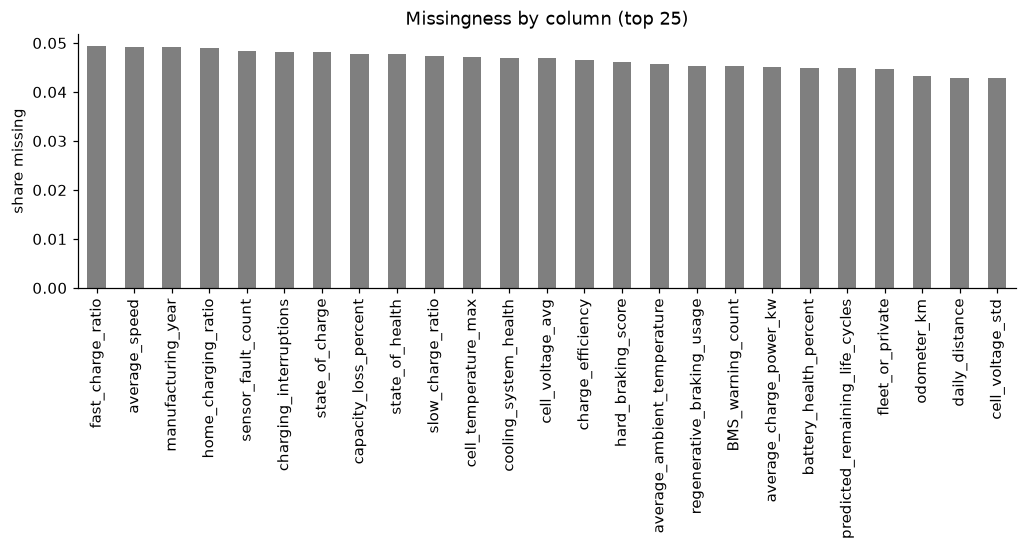

In [3]:
miss = df.isna().mean().sort_values(ascending=False)
print(f"Cells missing overall: {df.isna().mean().mean():.2%}; columns with any missing: {(miss > 0).sum()}")
ax = miss[miss > 0].head(25).plot.bar(figsize=(11, 3), color="tab:gray")
ax.set_ylabel("share missing"); ax.set_title("Missingness by column (top 25)"); plt.show()

→ **Decision:** missingness is low and diffuse (~4 %), not concentrated in a few columns, so
**median / mode imputation inside the sklearn pipeline** (fit on train only) is adequate, and the API
accepts partial payloads. The serving layer also exports the per-request missing-feature ratio as a
Prometheus metric, because a spike there means a broken upstream feed.

## 3. Which signals separate failing packs?

In [4]:
num = df.select_dtypes("number").columns.drop(TARGET)
auc = {}
for c in num:
    m = df[c].notna()
    a = roc_auc_score(df.loc[m, TARGET], df.loc[m, c])
    auc[c] = max(a, 1 - a)
auc = pd.Series(auc).sort_values(ascending=False)
auc.head(15).round(3).to_frame("single-feature AUC")

,single-feature AUC
thermal_runaway_risk,0.842
thermal_health_score,0.839
battery_health_percent,0.819
capacity_loss_percent,0.819
predicted_remaining_life_cycles,0.818
state_of_health,0.816
internal_resistance,0.800
cell_temperature_max,0.797
cell_temperature_avg,0.776
charge_efficiency,0.773


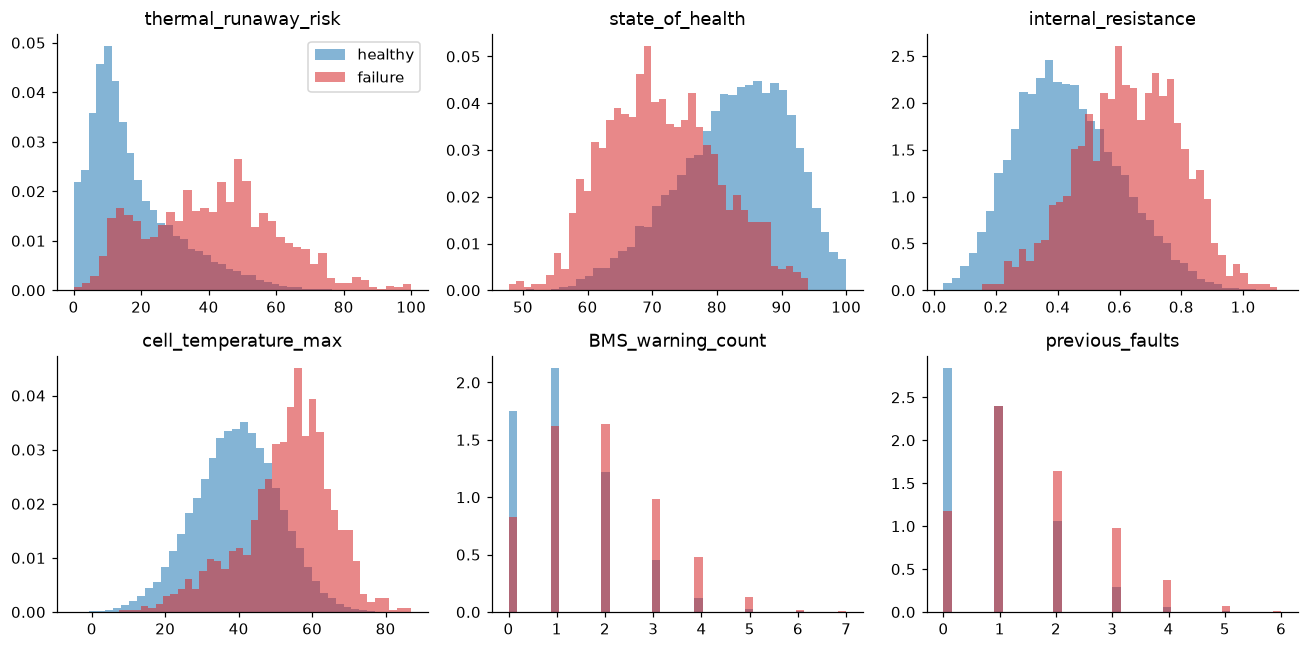

In [5]:
top = ["thermal_runaway_risk", "state_of_health", "internal_resistance",
       "cell_temperature_max", "BMS_warning_count", "previous_faults"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), top):
    for label, colour in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(df.loc[df[TARGET] == label, col].dropna(), bins=40, density=True,
                alpha=0.55, color=colour, label="failure" if label else "healthy")
    ax.set_title(col)
axes[0, 0].legend(); fig.tight_layout(); plt.show()

Failing packs show the expected physics: lower state of health, higher internal resistance,
hotter cells, more BMS warnings and prior faults.

→ **Decision:** no single feature exceeds AUC ≈ 0.85, so there is no obvious target leak. But 8
columns are *derived scores* of unknown provenance (`thermal_runaway_risk`, `aging_score`, …). The
pipeline gets a dedicated **`leakage_audit` stage** (single-feature AUC scan + ablation without the
derived scores) that runs on every retrain, instead of a one-off check in this notebook.

## 4. Categorical features

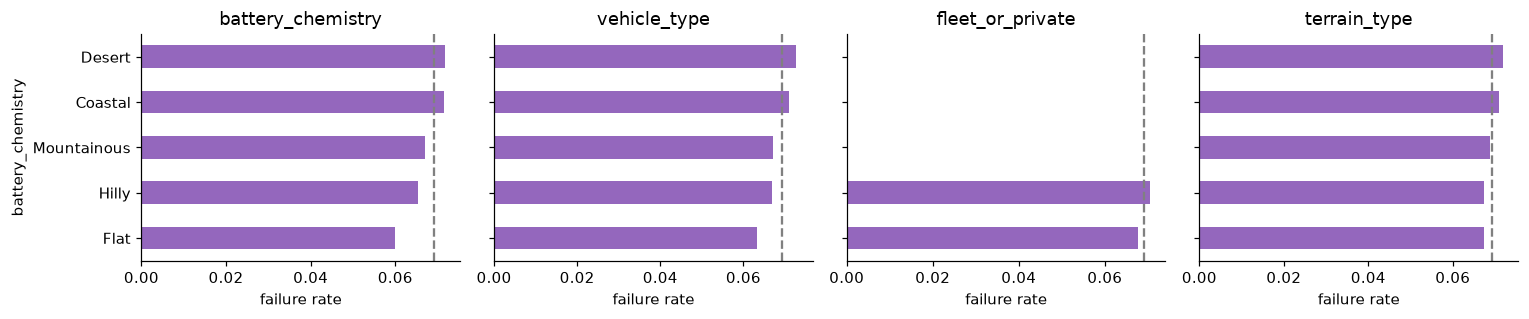

In [6]:
cats = ["battery_chemistry", "vehicle_type", "fleet_or_private", "terrain_type"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, col in zip(axes, cats):
    df.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax, color="tab:purple")
    ax.axvline(rate, ls="--", color="grey"); ax.set_title(col); ax.set_xlabel("failure rate")
fig.tight_layout(); plt.show()

In [7]:
pd.crosstab(df["vehicle_brand"], df["vehicle_type"]).head(8)

vehicle_type,Crossover,Hatchback,SUV,Sedan,Truck,Van
vehicle_brand,,,,,,
Audi,144,163,168,162,157,173
BMW,155,171,154,157,162,162
BYD,157,174,150,165,157,169
Ford,149,132,154,144,171,121
GM,171,154,152,129,160,161
Honda,146,157,168,156,146,184
Hyundai,160,177,147,163,156,148
Kia,161,166,144,164,149,170


Two red flags about the data's origin: failure rates are almost identical across chemistries
(real LFP, NMC and LTO cells age very differently), and every brand sells a near-uniform mix of
Trucks, Vans, Sedans and so on (a *Ford Mustang Mach-E* labelled *Truck*).

→ **Decision:** treat the dataset as **synthetic** and say so in the
[dataset card](../docs/DATASET_CARD.md) and README. The engineering transfers to real data; the headline
metrics do not.

## 5. Correlated feature groups

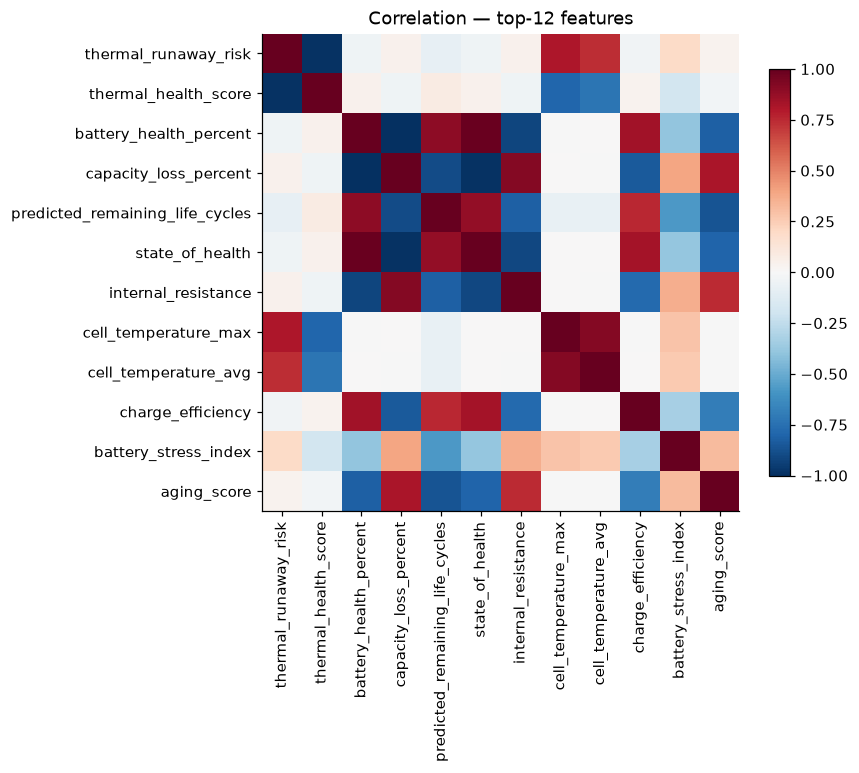

In [8]:
cols = auc.head(12).index
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90); ax.set_yticks(range(len(cols)), cols)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlation — top-12 features"); plt.show()

`state_of_health`, `battery_health_percent` and `capacity_loss_percent` are near-duplicates.

→ **Decision:** keep them. Regularised models (L2 logistic regression, gradient boosting) handle
collinearity well. When *explaining* predictions, credit is split between them, so SHAP values are read
per group rather than per column.

## Summary → pipeline design

| Finding | Pipeline decision |
|---|---|
| 6.9 % positives | PR-AUC for selection and gates; stratified 70/15/15 split; cost-based threshold |
| ~4 % diffuse missingness | Imputer inside the persisted sklearn transformer; missingness metric in serving |
| Strong but plausible single signals | `leakage_audit` DVC stage on every run |
| Derived scores of unknown origin | Ablation in the audit; documented in the model card |
| Data looks synthetic | Stated in dataset card, README and model card |
| Signal near-linear (step 3 histograms) | Include a regularised linear baseline; let CV decide (it won) |